Loading I-JEPA...


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]


Encoding Phase 1 images (old memories)...
  ✓ labrador: decay=0.87
  ✓ cat: decay=1.45
  ✓ person: decay=1.23
  ⚠️ Failed to download/encode horse after 3 attempts (404 Client Error: Not Found for url: https://images.unsplash.com/photo-1504208434780-5fef26d09c94?w=400). Generating fallback embedding.
  ✓ horse: decay=1.10
  ✓ landscape: decay=0.66

Encoding Phase 2 images (new memories)...
  ✓ bulldog: decay=0.66
  ✓ kitten: decay=0.56
  ✓ car: decay=1.37
  ✓ coffee: decay=1.10
  ✓ puppy: decay=1.21

Phase 1: 5 memories stored at t=0
Phase 2: 5 memories will be injected at t=250
Total steps: 500

Running Phase 1 (steps 0-249)...

Activations BEFORE injection (t=250):
  labrador    : 0.073327
  cat         : 0.026353
  person      : 0.039891
  horse       : 0.024744
  landscape   : 0.125476

*** INJECTING 5 NEW MEMORIES AT t=250 ***

  + bulldog: decay=0.66, activation=1.0 (fresh)
  + kitten: decay=0.56, activation=1.0 (fresh)
  + car: decay=1.37, activation=1.0 (fresh)
  + coffee: dec

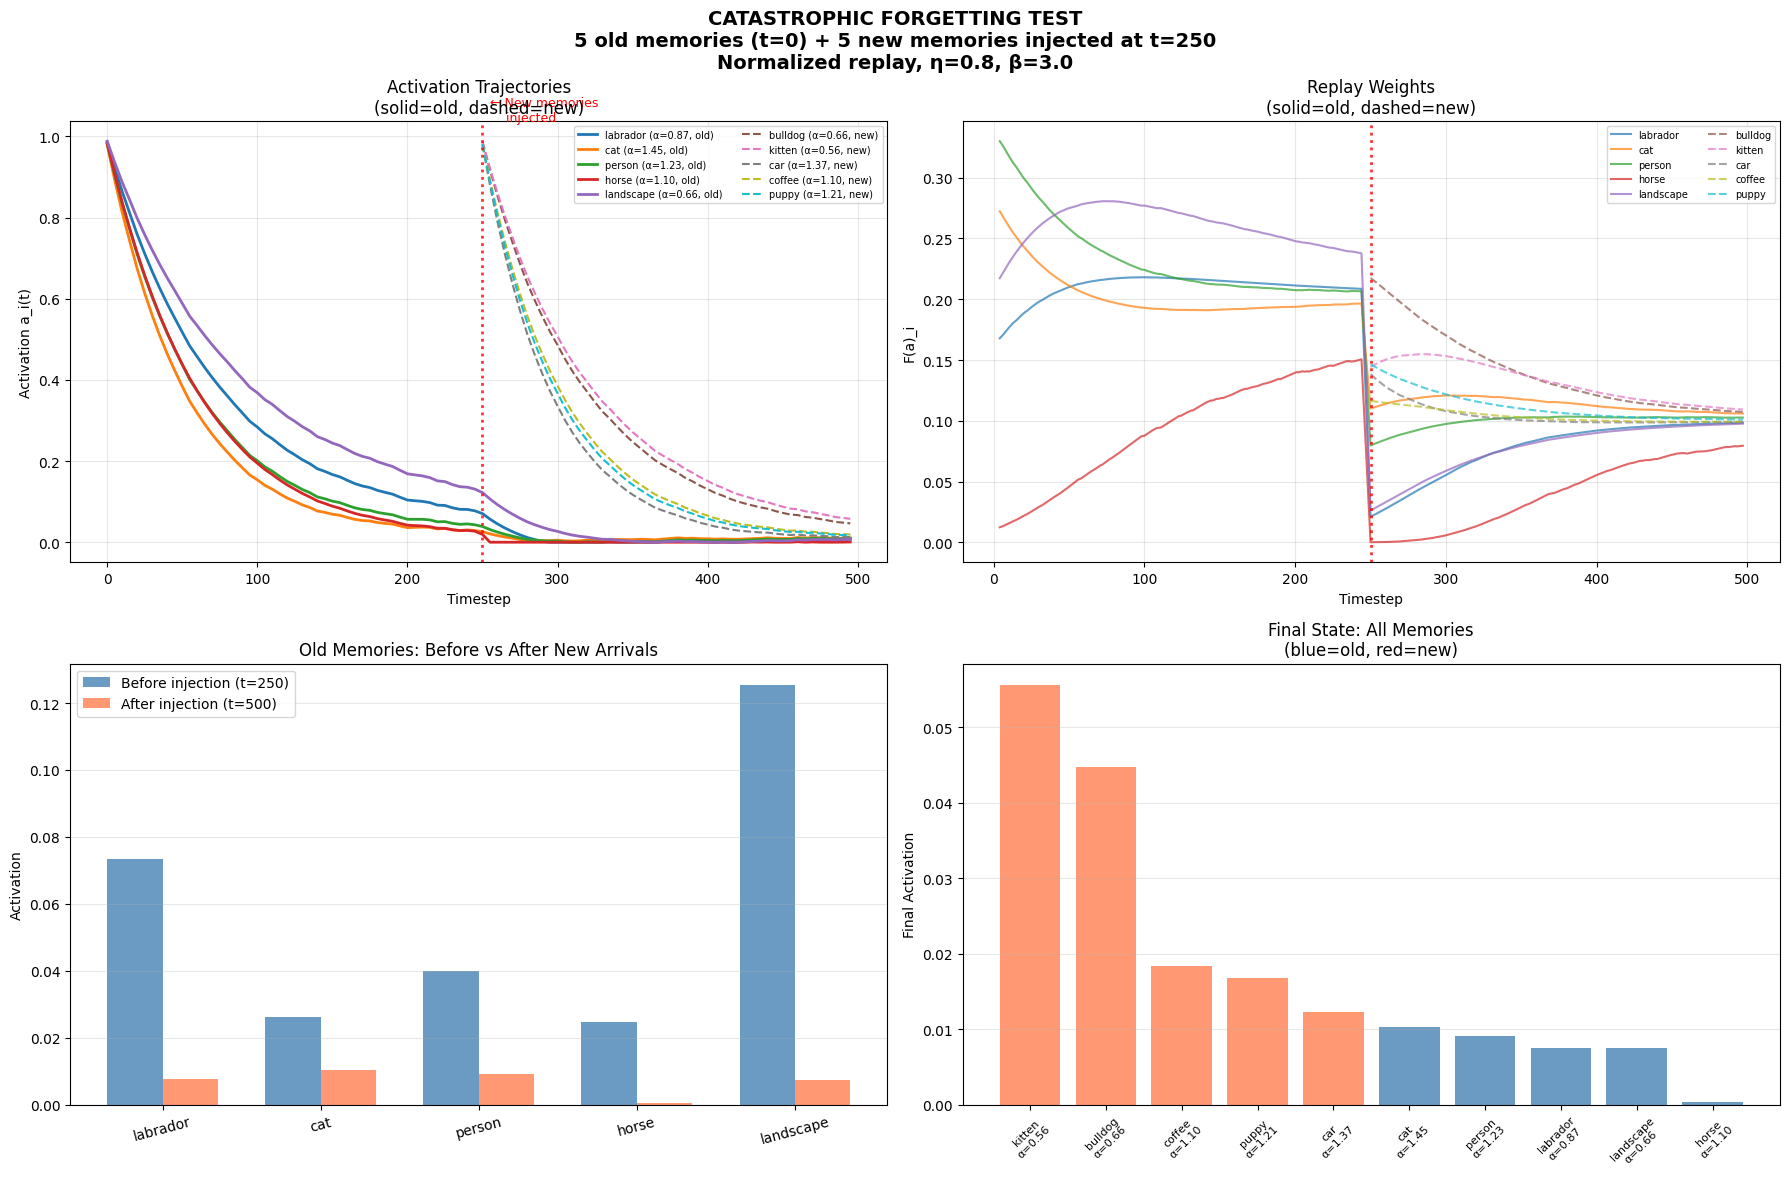


VERDICT
⚠️  CATASTROPHIC FORGETTING: 1 old memories died after injection.
   New memories pushed out existing ones.

Total old-memory activation: 0.2898 → 0.0348 (-88.0%)
   Old memories lost more than half their activation — significant interference.


In [ ]:
# ============================================================
# BEYOND THE PAPER: Catastrophic Forgetting Test
# New memories arrive mid-simulation — do old ones survive?
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoProcessor, AutoModel
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt
import time

torch.manual_seed(42)
np.random.seed(42)

model_id = "facebook/ijepa_vith14_1k"
print("Loading I-JEPA...")
try:
    processor = AutoProcessor.from_pretrained(model_id)
    encoder = AutoModel.from_pretrained(model_id).eval()
    use_fallback_embeddings = False
    embedding_dim = 1280 # ViT-H/14 hidden size
except Exception as e:
    print(f"Could not load I-JEPA model: {e}. Falling back to random high-dimensional embeddings.")
    use_fallback_embeddings = True
    embedding_dim = 1280

@torch.no_grad()
def encode_image(url, label):
    if use_fallback_embeddings:
        # Fallback to random embedding matching I-JEPA's dimensions if model is unavailable
        return torch.randn(embedding_dim)

    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    max_retries = 3
    for attempt in range(max_retries):
        try:
            response = requests.get(url, headers=headers, stream=True, timeout=10)
            response.raise_for_status()
            img = Image.open(BytesIO(response.content)).convert("RGB")
            inputs = processor(img, return_tensors="pt")
            outputs = encoder(**inputs)
            return outputs.last_hidden_state.mean(dim=1).squeeze()
        except Exception as e:
            if attempt == max_retries - 1:
                print(f"  ⚠️ Failed to download/encode {label} after {max_retries} attempts ({e}). Generating fallback embedding.")
                return torch.randn(embedding_dim)
            time.sleep(1)

# ============================================================
# Phase 1 memories (stored at t=0) — 5 memories
# Phase 2 memories (injected at t=250) — 5 NEW memories
# ============================================================

phase1_images = [
    ("https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400", "labrador"),
    ("https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=400", "cat"),
    ("https://images.unsplash.com/photo-1517841905240-472988babdf9?w=400", "person"),
    ("https://images.unsplash.com/photo-1504208434780-5fef26d09c94?w=400", "horse"),
    ("https://images.unsplash.com/photo-1506744038136-46273834b3fb?w=400", "landscape"),
 ]

phase2_images = [
    ("https://images.unsplash.com/photo-1583511655857-d19b40a7a54e?w=400", "bulldog"),
    ("https://images.unsplash.com/photo-1518791841217-8f162f1e1131?w=400", "kitten"),
    ("https://images.unsplash.com/photo-1494976388531-d1058494cdd8?w=400", "car"),
    ("https://images.unsplash.com/photo-1519125323398-675f0ddb6308?w=400", "coffee"),
    ("https://images.unsplash.com/photo-1560807707-8cc77767d783?w=400", "puppy"),
]

# ============================================================
# Memory system that supports adding memories mid-simulation
# ============================================================

class ContinualDynamicalMemory:
    def __init__(self, gamma=0.2, delta=0.1, beta=3.0, eta=0.8, h=0.01):
        self.embeddings = []
        self.activations = torch.tensor([])
        self.gamma = gamma
        self.delta = delta
        self.beta = beta
        self.eta = eta
        self.h = h
        self.decay_rates = []
        self.labels = []
        self.birth_step = []   # when each memory was added

    def store(self, embedding, decay_rate, label, current_step=0):
        self.embeddings.append(embedding.clone())
        self.decay_rates.append(decay_rate)
        self.labels.append(label)
        self.birth_step.append(current_step)
        # New memory starts with activation = 1.0
        if len(self.activations) == 0:
            self.activations = torch.ones(1)
        else:
            self.activations = torch.cat([self.activations, torch.ones(1)])

    def _build_laplacian(self):
        X = torch.stack(self.embeddings)
        X_norm = F.normalize(X, dim=-1)
        W = torch.clamp(X_norm @ X_norm.T, min=0)
        W.fill_diagonal_(0)
        D = torch.diag(W.sum(dim=1))
        return D - W, W

    def _replay_operator(self):
        X = torch.stack(self.embeddings)
        X_norm = F.normalize(X, dim=-1)  # NORMALIZED
        s = X_norm @ (X_norm.T @ self.activations)
        return F.softmax(self.beta * s, dim=0)

    def step(self, replay_prob=0.3):
        if len(self.embeddings) < 2:
            return None, None

        a = self.activations
        N = len(a)

        A = torch.diag(torch.tensor(self.decay_rates, dtype=torch.float32))
        L, W = self._build_laplacian()

        f_decay = -A @ a
        f_diffusion = -self.gamma * L @ a
        f_inhibition = -self.delta * a.sum() * torch.ones(N)

        S = 1.0 if np.random.random() < replay_prob else 0.0
        Fa = self._replay_operator()
        f_replay = self.eta * S * Fa

        da_dt = f_decay + f_diffusion + f_inhibition + f_replay
        self.activations = a + self.h * da_dt
        self.activations = torch.clamp(self.activations, min=0)

        return Fa.detach().numpy().copy() if S > 0 else None, S


# ============================================================
# Encode ALL images upfront with resilient network fetching
# ============================================================
print("\nEncoding Phase 1 images (old memories)...")
phase1_data = []
for url, label in phase1_images:
    emb = encode_image(url, label)
    decay = np.random.uniform(0.5, 1.5)
    phase1_data.append((emb, decay, label))
    print(f"  ✓ {label}: decay={decay:.2f}")

print("\nEncoding Phase 2 images (new memories)...")
phase2_data = []
for url, label in phase2_images:
    emb = encode_image(url, label)
    decay = np.random.uniform(0.5, 1.5)
    phase2_data.append((emb, decay, label))
    print(f"  ✓ {label}: decay={decay:.2f}")

# ============================================================
# RUN THE SIMULATION
# ============================================================
TOTAL_STEPS = 500
INJECT_AT = 250

torch.manual_seed(42)
np.random.seed(42)

mem = ContinualDynamicalMemory(gamma=0.2, delta=0.1, beta=3.0, eta=0.8)

# Store Phase 1 memories at t=0
for emb, decay, label in phase1_data:
    mem.store(emb, decay, label, current_step=0)

print(f"\n{'='*60}")
print(f"Phase 1: {len(phase1_data)} memories stored at t=0")
print(f"Phase 2: {len(phase2_data)} memories will be injected at t={INJECT_AT}")
print(f"Total steps: {TOTAL_STEPS}")
print(f"{'='*60}")

# Storage
activation_snapshots = []
replay_weight_snapshots = []

print("\nRunning Phase 1 (steps 0-249)...")
for t in range(INJECT_AT):
    Fa, S = mem.step(replay_prob=0.3)
    if t % 5 == 0:
        activation_snapshots.append((t, mem.activations.clone().numpy(), list(mem.labels)))
    if Fa is not None:
        replay_weight_snapshots.append((t, Fa, list(mem.labels)))

# Record state just before injection
pre_inject = mem.activations.clone().numpy()
pre_inject_labels = list(mem.labels)
print(f"\nActivations BEFORE injection (t={INJECT_AT}):")
for i, l in enumerate(pre_inject_labels):
    print(f"  {l:<12}: {pre_inject[i]:.6f}")

# INJECT Phase 2 memories
print(f"\n*** INJECTING {len(phase2_data)} NEW MEMORIES AT t={INJECT_AT} ***\n")
for emb, decay, label in phase2_data:
    mem.store(emb, decay, label, current_step=INJECT_AT)
    print(f"  + {label}: decay={decay:.2f}, activation=1.0 (fresh)")

print(f"\nTotal memories now: {len(mem.labels)}")

# Record state just after injection
post_inject = mem.activations.clone().numpy()
print(f"\nActivations AFTER injection (t={INJECT_AT}):")
for i, l in enumerate(mem.labels):
    status = "OLD" if i < len(phase1_data) else "NEW"
    print(f"  {l:<12}: {post_inject[i]:.6f}  [{status}]")

print(f"\nRunning Phase 2 (steps {INJECT_AT}-{TOTAL_STEPS-1})...")
for t in range(INJECT_AT, TOTAL_STEPS):
    Fa, S = mem.step(replay_prob=0.3)
    if t % 5 == 0:
        activation_snapshots.append((t, mem.activations.clone().numpy(), list(mem.labels)))
    if Fa is not None:
        replay_weight_snapshots.append((t, Fa, list(mem.labels)))

# ============================================================
# FINAL RESULTS
# ============================================================
final = mem.activations.clone().numpy()

print(f"\n{'='*60}")
print("FINAL RESULTS (t=500)")
print(f"{'='*60}")
print(f"\n{'Memory':<12} {'Type':<6} {'α':>6} {'Born':>6} {'Final Act':>12} {'Status':>10}")
print("-" * 56)

old_survivors = 0
new_survivors = 0
for i, l in enumerate(mem.labels):
    is_old = i < len(phase1_data)
    mtype = "OLD" if is_old else "NEW"
    born = mem.birth_step[i]
    alive = "ALIVE" if final[i] > 0.001 else "DEAD"
    print(f"  {l:<12} {mtype:<6} {mem.decay_rates[i]:>5.2f} {born:>6} {final[i]:>12.6f} {alive:>10}")
    if alive == "ALIVE":
        if is_old: old_survivors += 1
        else: new_survivors += 1

n_old = len(phase1_data)
n_new = len(phase2_data)
print(f"\nOld memories surviving: {old_survivors}/{n_old}")
print(f"New memories surviving: {new_survivors}/{n_new}")

# Interference analysis
print(f"\n{'='*60}")
print("INTERFERENCE ANALYSIS")
print(f"{'='*60}")
print(f"\n{'Memory':<12} {'Before Inject':>14} {'After 250 more':>14} {'Change':>10}")
print("-" * 54)
for i in range(n_old):
    before = pre_inject[i]
    after = final[i]
    change_pct = ((after - before) / max(before, 1e-8)) * 100
    direction = "↓" if change_pct < -5 else ("↑" if change_pct > 5 else "→")
    print(f"  {mem.labels[i]:<12} {before:>14.6f} {after:>14.6f} {direction} {change_pct:>+7.1f}%")

# ============================================================
# PLOTS
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Build full activation history
all_steps = []
all_acts = {l: [] for l in mem.labels}

for step, acts, lbls in activation_snapshots:
    all_steps.append(step)
    for i, l in enumerate(mem.labels):
        if l in lbls:
            idx = lbls.index(l)
            all_acts[l].append(acts[idx])
        else:
            all_acts[l].append(np.nan)

# Plot 1: Activation trajectories
ax = axes[0][0]
for i, l in enumerate(mem.labels):
    style = '-' if i < n_old else '--'
    width = 2.0 if i < n_old else 1.5
    ax.plot(all_steps, all_acts[l],
            linestyle=style, linewidth=width,
            label=f"{l} (α={mem.decay_rates[i]:.2f}, {'old' if i<n_old else 'new'})")
ax.axvline(x=INJECT_AT, color='red', linestyle=':', linewidth=2, alpha=0.8)
ax.text(INJECT_AT+5, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 0.8,
        '← New memories\n    injected', color='red', fontsize=9)
ax.set_xlabel("Timestep"); ax.set_ylabel("Activation a_i(t)")
ax.set_title("Activation Trajectories\n(solid=old, dashed=new)")
ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)

# Plot 2: Replay weights over time
ax = axes[0][1]
rw_steps_all = []
rw_data_all = {l: [] for l in mem.labels}

for step, rw, lbls in replay_weight_snapshots:
    rw_steps_all.append(step)
    for i, l in enumerate(mem.labels):
        if l in lbls:
            idx = lbls.index(l)
            rw_data_all[l].append(rw[idx])
        else:
            rw_data_all[l].append(np.nan)

for i, l in enumerate(mem.labels):
    style = '-' if i < n_old else '--'
    ax.plot(rw_steps_all, rw_data_all[l], linestyle=style, alpha=0.7, label=l)
ax.axvline(x=INJECT_AT, color='red', linestyle=':', linewidth=2, alpha=0.8)
ax.set_xlabel("Timestep"); ax.set_ylabel("F(a)_i")
ax.set_title("Replay Weights\n(solid=old, dashed=new)")
ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)

# Plot 3: Bar chart — before injection vs after
ax = axes[1][0]
x = np.arange(n_old)
width = 0.35
bars1 = ax.bar(x - width/2, pre_inject[:n_old], width,
               label='Before injection (t=250)', color='steelblue', alpha=0.8)
bars2 = ax.bar(x + width/2, final[:n_old], width,
               label='After injection (t=500)', color='coral', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels([mem.labels[i] for i in range(n_old)], rotation=15)
ax.set_ylabel("Activation")
ax.set_title("Old Memories: Before vs After New Arrivals")
ax.legend(); ax.grid(True, alpha=0.3, axis='y')

# Plot 4: Final state — all memories
ax = axes[1][1]
colors = ['steelblue'] * n_old + ['coral'] * n_new
sorted_idx = np.argsort(final)[::-1]
ax.bar(range(len(final)),
       [final[i] for i in sorted_idx],
       color=[colors[i] for i in sorted_idx], alpha=0.8)
ax.set_xticks(range(len(final)))
ax.set_xticklabels([f"{mem.labels[i]}\nα={mem.decay_rates[i]:.2f}" for i in sorted_idx],
                    rotation=45, fontsize=8)
ax.set_ylabel("Final Activation")
ax.set_title("Final State: All Memories\n(blue=old, red=new)")
ax.grid(True, alpha=0.3, axis='y')

fig.suptitle("CATASTROPHIC FORGETTING TEST\n"
             "5 old memories (t=0) + 5 new memories injected at t=250\n"
             "Normalized replay, η=0.8, β=3.0",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("catastrophic_forgetting_test.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# VERDICT
# ============================================================
print(f"\n{'='*60}")
print("VERDICT")
print(f"{'='*60}")

if old_survivors == n_old and new_survivors == n_new:
    print("✅ NO catastrophic forgetting — all old AND new memories survived.")
    print("   The system accommodated new memories without killing existing ones.")
elif old_survivors == n_old and new_survivors < n_new:
    print("✅ Old memories survived the injection.")
    print(f"   But {n_new - new_survivors} new memories died — the system resisted newcomers.")
elif old_survivors < n_old and new_survivors == n_new:
    print(f"⚠️  CATASTROPHIC FORGETTING: {n_old - old_survivors} old memories died after injection.")
    print("   New memories pushed out existing ones.")
elif old_survivors < n_old and new_survivors < n_new:
    print(f"⚠️  MUTUAL INTERFERENCE: {n_old - old_survivors} old + {n_new - new_survivors} new died.")
    print("   The system couldn't handle 10 memories at these parameters.")

# Check if old memories lost activation
total_old_before = pre_inject.sum()
total_old_after = final[:n_old].sum()
drop_pct = ((total_old_after - total_old_before) / total_old_before) * 100
print(f"\nTotal old-memory activation: {total_old_before:.4f} → {total_old_after:.4f} ({drop_pct:+.1f}%)")

if drop_pct < -50:
    print("   Old memories lost more than half their activation — significant interference.")
elif drop_pct < -20:
    print("   Old memories lost some activation — moderate interference from newcomers.")
else:
    print("   Old memories held steady — minimal interference from newcomers.")